<a href="https://colab.research.google.com/github/Innej3/PatientZero/blob/main/PatientZero-SI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from matplotlib.gridspec import GridSpec
import matplotlib.animation as animation

In [ ]:
'''
OBJECTIVE: Given only the infected nodes in an SUSCEPTIBLE-INFECTED (SI) outbreak,
could we locate the source ?

We used 3 graph topologies
Erdos Renyi (ER)
Barabasi Albert (BA)
Watts-Strogatz (WS)

Tested on three methods:
ABC Approximate Bayesian Computation
Jordan Centrality (Min-Max eccentricity inside G_I)
Rumor Centrality (Tree MLE)

'''

In [ ]:
def generate_topology(case='BA', n=90, seed=42):
  rng = np.random.default_rng(seed)
  if case == 'ER':
    G = nx.erdos_renyi_graph(n, p=0.065, seed=seed)
  elif case == 'BA':
    G = nx.barabasi_albert_graph(n, 2, seed=seed)
  elif case == 'WS':
    G = nx.watts_strogatz_graph(n, 4, 0.15, seed=seed)
  else:
    raise ValueError('Invalid TOPO')

  if not nx.is_connected(G):
    largest_cc = max(nx.connected_components(G), key=len)
    G = G.subgraph(largest_cc).copy()
    G = nx.convert_node_labels_to_integers(G)

  degrees = dict(G.degree())
  max_hub = max(degrees, key=degrees.get)


  if case == 'BA':
    lengths = nx.single_source_shortest_path_length(G, max_hub)
    candidates = [u for u,d in lengths.items() if d==2 and degrees[u] <= 2]
    patient_zero = candidates[0] if candidates else rng.choice(list(G.nodes()))
  else:
    patient_zero = rng.choice(list(G.nodes()))

  pos = nx.spring_layout(G, k=0.38, iterations=80, seed=seed)
  return G, pos, patient_zero, max_hub

In [ ]:
def simulate_si(G, source, beta=0.32, max_infected_frac=0.65, seed=42):
  '''
  DiSCRETE-TIME SUSCEPTIBLE OR INFECTED cascade simulation, NO RECOVERY
  each susceptible node v has k infected neighbors and each gets independent try
  at prob Beta, V escapes if all k fail:
  P(v infected this step) = 1 - (1 - Beta) ^k

  only one infected neighbor has to succeed in infecting v
  '''
  rng = np.random.default_rng(seed)
  infected = {source}
  history = [frozenset(infected)]
  target_size = int(len(G) * max_infected_frac)

  adj = {u: list(G.neighbors(u)) for u in G.nodes()}

  steps = 0
  while len(infected) < target_size and steps < 100:
    steps += 1
    new_infected = set()
    for u in infected:
      for v in adj[u]:
        if v not in infected:
          if rng.random() < beta:
            new_infected.add(v)

    if new_infected:
      infected.update(new_infected)
      history.append(frozenset(infected))

  return history

In [ ]:
'''
Jordan Center
if infection spreads outward like ripples, the source should be in the centre.
For each node it measures how far away its farthest infected node is (eccentricity);
the node with the smallest value is the centre.


'''

In [ ]:
def jordan_posterior(G, infected_set, tau=0.6):
  '''
  Jordan Centrality (min-max eccentricity inside G_I)
  '''
  G_I = G.subgraph(infected_set)
  post = np.zeros(len(G))
  if len(infected_set) == 1:
    only_node = next(iter(infected_set))
    post[only_node] = 1.0
    return post

  ecc = {}
  for v in infected_set:
    lengths = nx.single_source_shortest_path_length(G_I, v)
    ecc[v] = max(lengths.values())

  min_ecc = min(ecc.values())
  logits = np.array([-(ecc[v] - min_ecc) / tau for v in infected_set])
  weights = np.exp(logits)
  weights /= weights.sum()

  for v, w in zip(infected_set, weights):
    post[v] = w
  return post

In [ ]:
def compute_rumor_posterior(G, infected_set, temp=2.5):
  """
  Shah-zaman Rumor Centrality - in how many different orders could the infection have
  spread if it started at v? the more possible ordering the more likely v is the source
  Rumor centrality assigns a score to every node in the infected subgraph.
  The node with the highest score is identified as the estimated source
  (the "rumor center").

  Since our network has cycles, we use build a BFS tree from each candidate root:
  keeping only the first edges that reaches each node.
  """
  G_I = G.subgraph(infected_set)
  post = np.zeros(len(G))
  if len(infected_set) == 1:
    only_node = next(iter(infected_set))
    post[only_node] = 1.0
    return post

  log_scores = {}
  for root in infected_set:
    bfs_edges = list(nx.bfs_edges(G_I, root))
    children = {u: [] for u in infected_set}
    order = [root]
    for u, v in bfs_edges:
      children[u].append(v)
      order.append(v)

    subtree_size = {u: 1 for u in infected_set}
    for u in reversed(order):
      for ch in children[u]:
        subtree_size[u] += subtree_size[ch]

    log_scores[root] = -sum(np.log(subtree_size[u]) / temp for u in infected_set)

  max_log = max(log_scores.values())
  weights = np.array([np.exp(log_scores[v] - max_log) for v in infected_set])
  weights /= weights.sum()

  for v, w in zip(infected_set, weights):
    post[v] = w
  return post


In [ ]:
def compute_abc_posterior(G, infected_set, beta=0.32, n_trails=60, epsilon=0.12, seed=101):
  '''
  P(v| observed) ∝ P(observed| v) P(v)
  P(v) - uniform prior
  P(obs| v) we approx it by simulatiion hence ABC method (Approximate Bayesian Computation)

  Jaccard Similarity = intersection / union

  It assumes Beta value is known, but in real life we wouldnt know Beta value

  '''
  post = np.zeros(len(G))
  target_size = len(infected_set)
  if target_size == 1:
    only_node = next(iter(infected_set))
    post[only_node] = 1.0
    return post

  rng = np.random.default_rng(seed)
  adj = {u: list(G.neighbors(u)) for u in G.nodes()}
  scores= {}

  for candidate in infected_set:
    jaccard_sum = 0.0
    for _ in range(n_trails):
      sim_inf = {candidate}
      frontier = [candidate]

      steps = 0
      while len(sim_inf) < target_size and steps < 60:
        steps += 1
        newly_added = []
        for u in list(sim_inf):
          for nb in adj[u]:
            if nb not in sim_inf and rng.random() < beta:
              sim_inf.add(nb)
              newly_added.append(nb)
              if len(sim_inf) >= target_size:
                break
          if len(sim_inf) >= target_size:
            break
        if not newly_added and len(sim_inf) < target_size:
          boundary = [nb for u in sim_inf for nb in adj[u] if nb not in sim_inf]
          if not boundary:
            break
          sim_inf.add(rng.choice(boundary))
      inter = len(sim_inf.intersection(infected_set))
      union = len(sim_inf.union(infected_set))
      jacc = inter/ union
      jaccard_sum += np.exp((jacc - 1.0) / epsilon)

    scores[candidate] = jaccard_sum / n_trails
  total = sum(scores.values())
  for v in infected_set:
    post[v] = scores[v] / total if total > 0 else 1.0/target_size
  return post

In [ ]:
def shannon_entropy(posterior):
  '''
  H = - sum(p * log2(p))
  '''
  p = posterior[posterior > 1e-12]
  return -np.sum(p * np.log2(p))

In [ ]:
def build_case_animation(case="BA", filename="patient_zero_BA.gif", n=85, beta=0.30, seed=7):
    print(f"[{case}] Generating topology and simulating SI cascade...")
    G, pos, source, max_hub = generate_topology(case=case, n=n, seed=seed)
    history = simulate_si(G, source, beta=beta, max_infected_frac=0.65, seed=seed)

    n_frames = len(history)
    print(f"[{case}] Cascade captured {n_frames} infection waves. Computing posteriors...")

    # Precompute posteriors and entropies for all frames
    jordan_frames, rumor_frames, abc_frames = [], [], []
    ent_jordan, ent_rumor, ent_abc = [], [], []
    hub_hit_frame = None

    for t, inf_set in enumerate(history):
        if hub_hit_frame is None and max_hub in inf_set:
            hub_hit_frame = t

        p_j = jordan_posterior(G, inf_set)
        p_r = compute_rumor_posterior(G, inf_set)
        p_a = compute_abc_posterior(G, inf_set, beta=beta, n_trails=50, seed=seed + t)

        jordan_frames.append(p_j)
        rumor_frames.append(p_r)
        abc_frames.append(p_a)

        ent_jordan.append(shannon_entropy(p_j))
        ent_rumor.append(shannon_entropy(p_r))
        ent_abc.append(shannon_entropy(p_a))

    # Set up dark-mode dashboard figure
    plt.style.use("dark_background")
    fig = plt.figure(figsize=(15, 8.5), facecolor="#0d1117")
    gs = GridSpec(2, 3, height_ratios=[1.85, 1.0], hspace=0.28, wspace=0.15, figure=fig)

    ax_j = fig.add_subplot(gs[0, 0])
    ax_r = fig.add_subplot(gs[0, 1])
    ax_a = fig.add_subplot(gs[0, 2])
    ax_ent = fig.add_subplot(gs[1, :2])
    ax_prob = fig.add_subplot(gs[1, 2])

    node_list = list(G.nodes())
    xy = np.array([pos[u] for u in node_list])
    degrees = np.array([G.degree(u) for u in node_list])
    base_sizes = 55 + 14 * degrees

    def update(frame):
        for ax in (ax_j, ax_r, ax_a, ax_ent, ax_prob):
            ax.clear()
            ax.set_facecolor("#161b22")

        inf_set = history[frame]
        estimators = [
            ("Jordan Centrality (Min-Max)", jordan_frames[frame], ax_j),
            ("Rumor Centrality (Tree MLE)", rumor_frames[frame], ax_r),
            ("Monte Carlo ABC (Boundary-Aware)", abc_frames[frame], ax_a),
        ]

        for title, post, ax in estimators:
            # Draw edges
            nx.draw_networkx_edges(
                G, pos, ax=ax, edge_color="#30363d", width=0.8, alpha=0.6
            )
            # Highlight active infected subgraph edges
            G_I = G.subgraph(inf_set)
            nx.draw_networkx_edges(
                G_I, pos, ax=ax, edge_color="#ff7b72", width=1.5, alpha=0.75
            )

            # Color uninfected nodes dark gray, infected nodes by posterior probability
            max_p = max(post.max(), 1e-6)
            colors = []
            for u in node_list:
                if u in inf_set:
                    colors.append(plt.cm.plasma(post[u] / max_p))
                else:
                    colors.append((0.18, 0.21, 0.25, 0.5))

            ax.scatter(
                xy[:, 0], xy[:, 1], s=base_sizes, c=colors,
                edgecolors="#c9d1d9", linewidths=0.5, zorder=3
            )

            # Mark True Patient Zero (Cyan Star/Ring)
            ax.scatter(
                [pos[source][0]], [pos[source][1]], s=260,
                facecolors="none", edgecolors="#00f5d4", linewidths=2.5,
                label="True Patient Zero", zorder=5
            )

            # Mark MAP Estimate (White Cross)
            map_node = int(np.argmax(post))
            ax.scatter(
                [pos[map_node][0]], [pos[map_node][1]], s=140,
                marker="X", c="#ffffff", edgecolors="#000000", linewidths=0.8,
                label=f"MAP Est (p={post[map_node]:.2f})", zorder=6
            )

            ax.set_title(
                f"{title}\nP(True Source) = {post[source]:.1%}",
                fontsize=10.5, fontweight="bold", color="#e6edf3", pad=8
            )
            ax.set_xticks([])
            ax.set_yticks([])

        # Bottom-Left: Shannon Entropy Horizon Chart
        t_axis = np.arange(frame + 1)
        ax_ent.plot(t_axis, ent_jordan[:frame + 1], "-o", color="#f78166", label="Jordan Entropy", lw=2)
        ax_ent.plot(t_axis, ent_rumor[:frame + 1], "-s", color="#d2a8ff", label="Rumor Entropy", lw=2)
        ax_ent.plot(t_axis, ent_abc[:frame + 1], "-^", color="#3fb950", label="ABC Entropy", lw=2.5)
        ax_ent.plot(
            np.arange(n_frames),
            [ np.log2(len(h)) for h in history ],
            "--", color="#8b949e", alpha=0.6, label="Max Uniform Entropy log2(|V_I|)"
        )

        if hub_hit_frame is not None:
            ax_ent.axvline(hub_hit_frame, color="#ff4b4b", linestyle=":", lw=2, label=f"Hub Hit (t={hub_hit_frame})")

        ax_ent.set_xlim(0, max(n_frames - 1, 1))
        ax_ent.set_ylim(0, np.log2(len(G)) + 0.5)
        ax_ent.set_title("Posterior Uncertainty (Shannon Entropy H(t) in Bits)", fontsize=10.5, fontweight="bold")
        ax_ent.set_xlabel("Cascade Wave (t)")
        ax_ent.set_ylabel("Entropy (bits)")
        ax_ent.legend(loc="upper left", fontsize=8, framealpha=0.3)
        ax_ent.grid(True, color="#30363d", alpha=0.4)

        # Bottom-Right: True Source Posterior Confidence over Time
        p_src_j = [p[source] for p in jordan_frames[:frame + 1]]
        p_src_r = [p[source] for p in rumor_frames[:frame + 1]]
        p_src_a = [p[source] for p in abc_frames[:frame + 1]]

        ax_prob.plot(t_axis, p_src_j, "-o", color="#f78166", label="Jordan P(v*)", lw=2)
        ax_prob.plot(t_axis, p_src_r, "-s", color="#d2a8ff", label="Rumor P(v*)", lw=2)
        ax_prob.plot(t_axis, p_src_a, "-^", color="#3fb950", label="ABC P(v*)", lw=2.5)

        if hub_hit_frame is not None:
            ax_prob.axvline(hub_hit_frame, color="#ff4b4b", linestyle=":", lw=2)

        ax_prob.set_xlim(0, max(n_frames - 1, 1))
        ax_prob.set_ylim(0, 1.05)
        ax_prob.set_title("Probability Assigned to True Patient Zero P(v* | G_I)", fontsize=10.5, fontweight="bold")
        ax_prob.set_xlabel("Cascade Wave (t)")
        ax_prob.set_ylabel("P(v*)")
        ax_prob.legend(loc="upper right", fontsize=8, framealpha=0.3)
        ax_prob.grid(True, color="#30363d", alpha=0.4)

        fig.suptitle(
            f"Patient Zero Localization — {case} Network (N={len(G)}, Infected={len(inf_set)}/{len(G)} at t={frame})   "
            f"[Cyan Ring = True Source | White X = Estimator Guess]",
            fontsize=12.5, fontweight="bold", color="#58a6ff", y=0.97
        )

    anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=900, repeat=True)
    anim.save(filename, writer="pillow", fps=1.2)
    plt.close(fig)
    print(f"[{case}] Saved animated GIF -> {filename}\n")

In [ ]:
build_case_animation(case="BA", filename="patient_zero_BA_scale_free.gif", n=85, beta=0.28, seed=11)

[BA] Generating topology and simulating SI cascade...
[BA] Cascade captured 6 infection waves. Computing posteriors...
[BA] Saved animated GIF -> patient_zero_BA_scale_free.gif



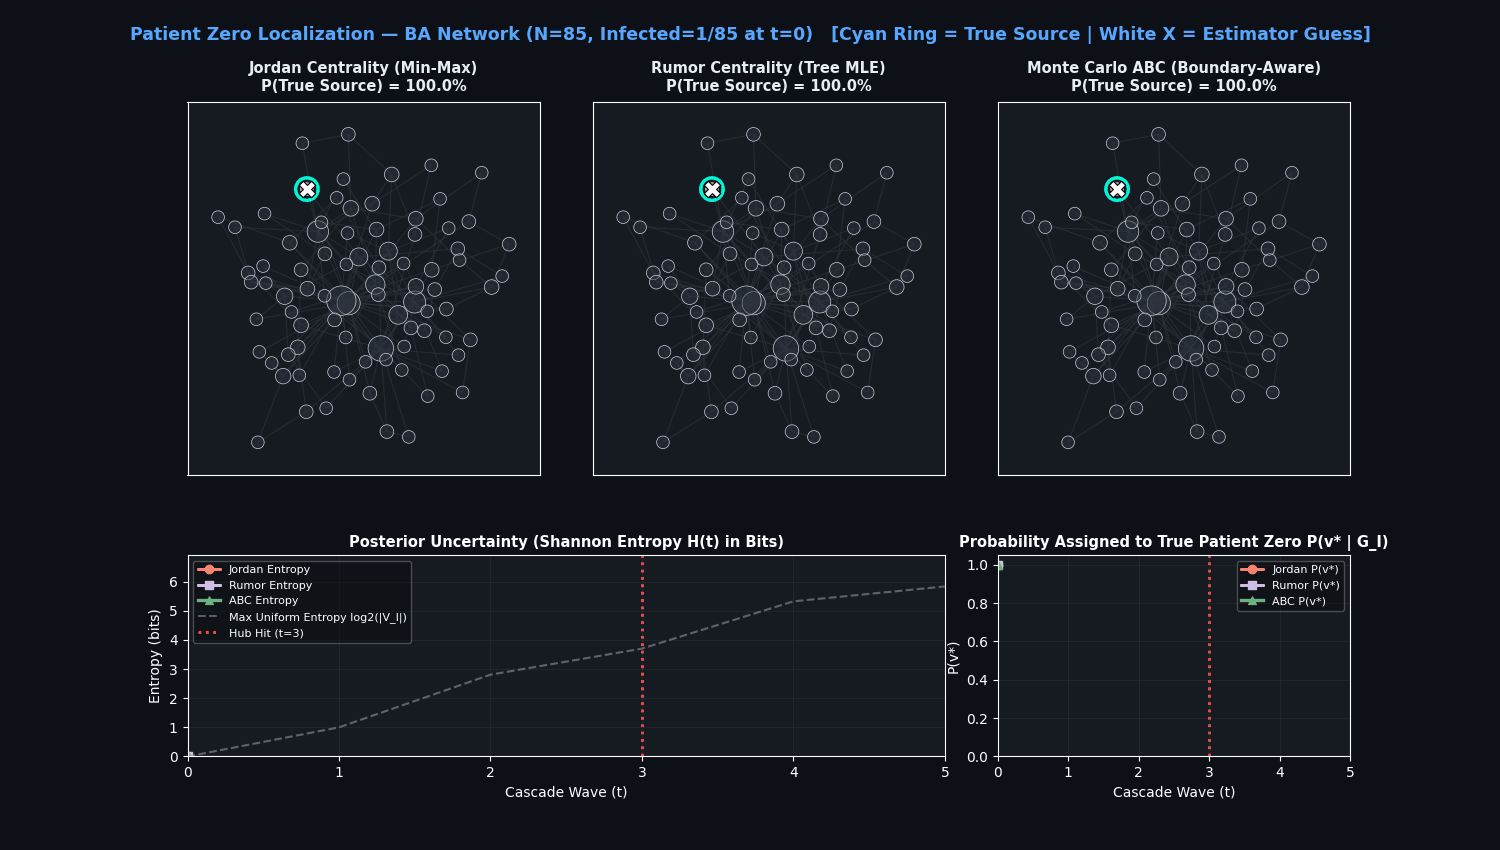

In [ ]:
from IPython import display
display.Image(filename='patient_zero_BA_scale_free.gif')

In [ ]:
build_case_animation(case="ER", filename="patient_zero_ER_random.gif", n=85, beta=0.28, seed=11)

[ER] Generating topology and simulating SI cascade...
[ER] Cascade captured 8 infection waves. Computing posteriors...
[ER] Saved animated GIF -> patient_zero_ER_random.gif



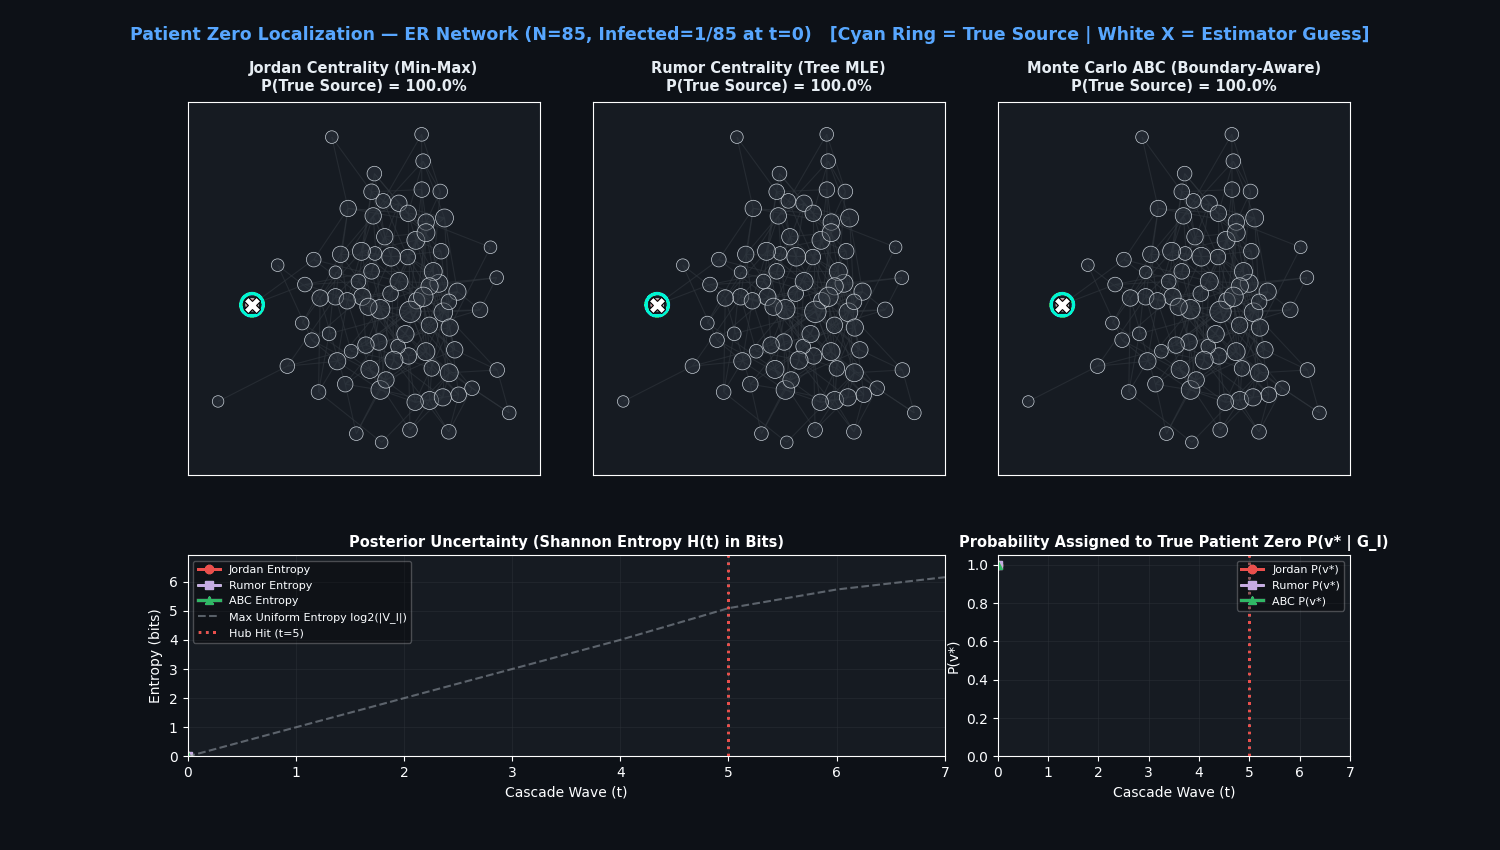

In [ ]:
from IPython import display
display.Image(filename='patient_zero_ER_random.gif')

In [ ]:
build_case_animation(case="WS", filename="patient_zero_WS_small_world.gif", n=85, beta=0.28, seed=11)

[WS] Generating topology and simulating SI cascade...
[WS] Cascade captured 9 infection waves. Computing posteriors...
[WS] Saved animated GIF -> patient_zero_WS_small_world.gif



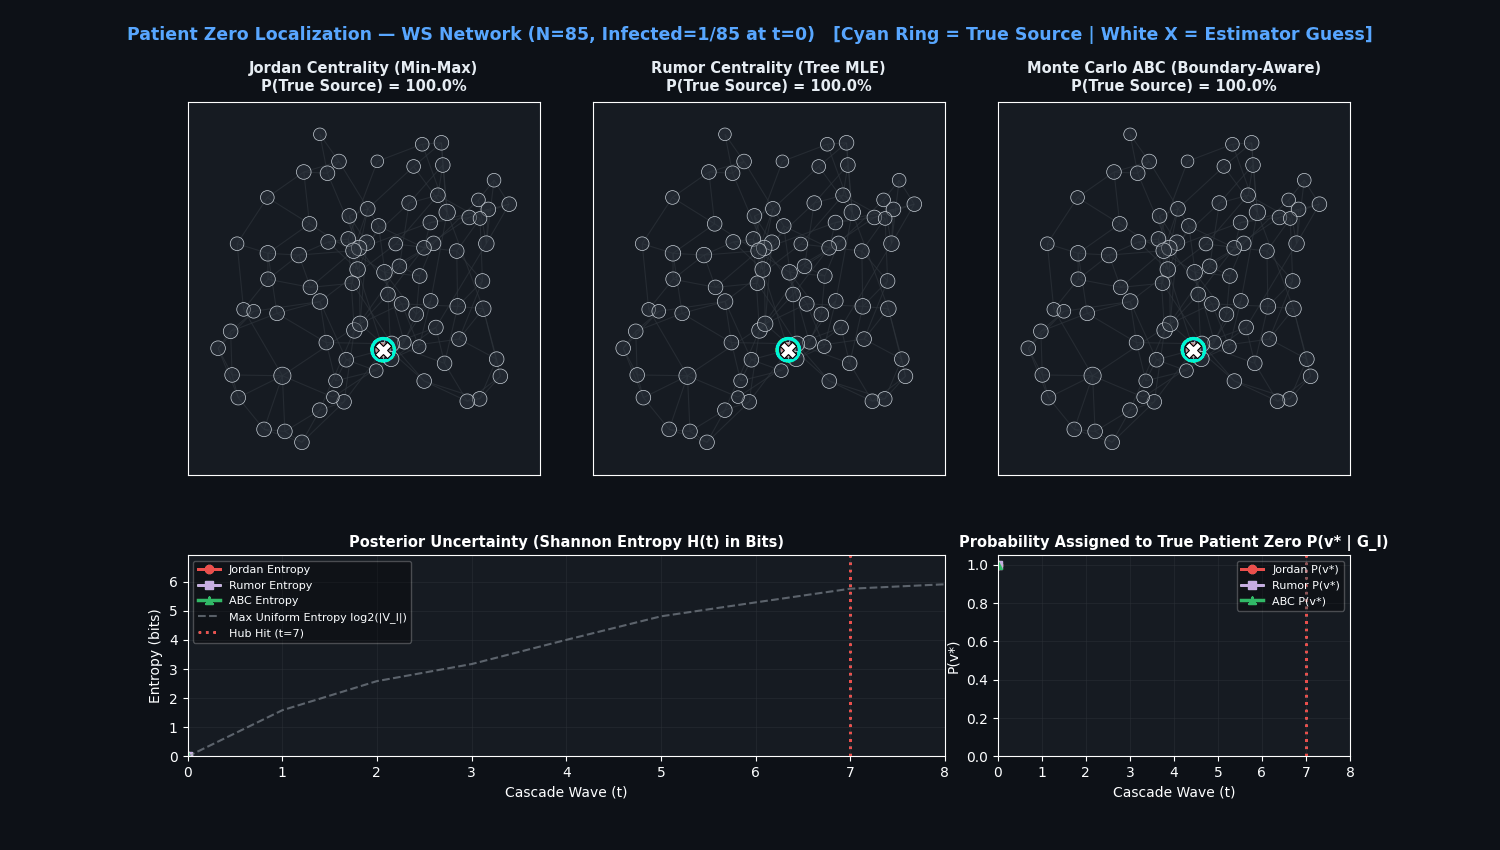

In [ ]:
from IPython import display
display.Image(filename='patient_zero_WS_small_world.gif')

In [ ]:
def evaluate(case, n_runs=100, beta=0.3, frac=0.3, n_trials=30):
  names = ['jordan', 'rumor', 'abc']
  res = {k: {'top1': [], 'rank': [], 'dist': []} for k in names}
  base_top1 = []
  base_rank, base_dist = [], []

  for r in range(n_runs):
    G, pos, _, hub = generate_topology(case=case, n=85, seed=r)
    rng = np.random.default_rng(1000 + r)
    src = int(rng.choice(list(G.nodes())))
    hist = simulate_si(G, src, beta=beta, max_infected_frac=0.95, seed=r)
    target = int(frac * len(G))
    inf = next((h for h in hist if len(h) >= target), hist[-1])

    inf_list = list(inf)
    base_top1.append(1 / len(inf))
    base_rank.append((len(inf) + 1) / 2)
    base_dist.append(np.mean([nx.shortest_path_length(G, int(u), src) for u in inf_list]))

    posts = {
      'jordan': jordan_posterior(G, inf),
      'rumor':  compute_rumor_posterior(G, inf),
      'abc':    compute_abc_posterior(G, inf, beta=beta, n_trails=n_trials, seed=r),
    }
    for k, post in posts.items():
      p_src = post[src]
      higher = int((post > p_src + 1e-12).sum())
      ties = int((np.abs(post - p_src) <= 1e-12).sum())
      res[k]['top1'].append((higher == 0) / ties)
      res[k]['rank'].append(higher + (ties + 1) / 2)
      best = np.flatnonzero(np.abs(post - post.max()) <= 1e-12)
      res[k]['dist'].append(np.mean([nx.shortest_path_length(G, int(b), src) for b in best]))

  print(f"\n{case}  (frac={frac})  random guess: top-1 {np.mean(base_top1):.2f}, "
        f"rank {np.median(base_rank):.0f}, hops {np.mean(base_dist):.2f}")
  for k in names:
    print(f"  {k:7s} top-1 {np.mean(res[k]['top1']):.2f}   median rank {np.median(res[k]['rank']):.0f}"
          f"   mean hops from guess to source {np.mean(res[k]['dist']):.2f}")
  return res


In [ ]:
results = {case: evaluate(case, n_runs=100) for case in ['ER', 'BA', 'WS']}


ER  (frac=0.3)  random guess: top-1 0.03, rank 18, hops 2.29
  jordan  top-1 0.20   median rank 8   mean hops from guess to source 1.46
  rumor   top-1 0.13   median rank 5   mean hops from guess to source 1.47
  abc     top-1 0.22   median rank 3   mean hops from guess to source 1.19

BA  (frac=0.3)  random guess: top-1 0.03, rank 16, hops 2.36
  jordan  top-1 0.05   median rank 12   mean hops from guess to source 1.67
  rumor   top-1 0.04   median rank 11   mean hops from guess to source 1.46
  abc     top-1 0.14   median rank 4   mean hops from guess to source 1.60

WS  (frac=0.3)  random guess: top-1 0.04, rank 14, hops 2.82
  jordan  top-1 0.24   median rank 3   mean hops from guess to source 1.20
  rumor   top-1 0.20   median rank 4   mean hops from guess to source 1.45
  abc     top-1 0.29   median rank 3   mean hops from guess to source 1.01


In [ ]:
'''
ABC is the best estimator overall, with the best median rank
Rumor Centrality is the weakest, makes sense as its exact only on trees, and these
networks are full of cycles.
'''

In [ ]:
def evaluate_ba(source_mode='random', n_runs=60, beta=0.3, frac=0.3, n_trials=30):
  out = {k: {'rank': [], 'hub_guess': []} for k in ['jordan', 'rumor', 'abc']}
  used = 0
  for r in range(n_runs):
    G, pos, _, hub = generate_topology(case='BA', n=85, seed=r)
    deg = dict(G.degree())
    if source_mode == 'trap':
      d = nx.single_source_shortest_path_length(G, hub)
      cand = [u for u, dist in d.items() if dist == 2 and deg[u] <= 2]
      if not cand:
        continue
      src = int(np.random.default_rng(2000 + r).choice(cand))
    else:
      src = int(np.random.default_rng(1000 + r).choice(list(G.nodes())))
    hist = simulate_si(G, src, beta=beta, max_infected_frac=0.95, seed=r)
    inf = next((h for h in hist if len(h) >= int(frac * len(G))), hist[-1])
    used += 1
    posts = {
      'jordan': jordan_posterior(G, inf),
      'rumor':  compute_rumor_posterior(G, inf),
      'abc':    compute_abc_posterior(G, inf, beta=beta, n_trails=n_trials, seed=r),
    }
    for k, post in posts.items():
      p_src = post[src]
      higher = int((post > p_src + 1e-12).sum())
      ties = int((np.abs(post - p_src) <= 1e-12).sum())
      out[k]['rank'].append(higher + (ties + 1) / 2)
      best = np.flatnonzero(np.abs(post - post.max()) <= 1e-12)
      out[k]['hub_guess'].append(np.mean(best == hub))
  print(f"\nBA source={source_mode}  ({used} runs)")
  for k, v in out.items():
    print(f"  {k:7s} median rank {np.median(v['rank']):.1f}   guesses the hub {np.mean(v['hub_guess']):.2f}")

In [ ]:
evaluate_ba('random')


BA source=random  (60 runs)
  jordan  median rank 12.2   guesses the hub 0.25
  rumor   median rank 11.0   guesses the hub 0.42
  abc     median rank 5.0   guesses the hub 0.03


In [ ]:
evaluate_ba('trap')


BA source=trap  (60 runs)
  jordan  median rank 15.8   guesses the hub 0.21
  rumor   median rank 20.0   guesses the hub 0.46
  abc     median rank 5.0   guesses the hub 0.00


In [ ]:
'''
Rumor centrality was proven to be the optimal Maximum Likelihood Estimator (MLE) f
or finding the source only under the strict condition that the underlying
network is a regular tree—a tree where every node has the same number of neighbours.
In that idealised, homogeneous setting, its mathematical guarantees hold


Scale-free networks violate this assumption completely.
They are defined by a power-law degree distribution, meaning they contain
a small number of "superstar" hubs with extremely high degree, alongside many
low-degree nodes


The centrality score is calculated by counting the number of possible
spreading orders that could originate from a candidate node. A hub, by
virtue of its many connections, creates a massive number of plausible branching paths.
The formula essentially rewards this structural potential, causing the hub to achieve
a very high centrality score regardless of whether it was actually the true source


Approximate Bayesian Computation (ABC) does not rely on a static,
topology-based score. Instead, it works by simulating the actual spreading process
many times and comparing the resulting outbreak patterns to the observed pattern.

'''

In [ ]:
def abc_wrong_beta(abc_beta, source_mode='trap', n_runs=40, beta=0.3, frac=0.3, n_trials=30):
  ranks, hub = [], []
  for r in range(n_runs):
    G, pos, _, h = generate_topology(case='BA', n=85, seed=r)
    deg = dict(G.degree())
    if source_mode == 'trap':
      d = nx.single_source_shortest_path_length(G, h)
      cand = [u for u, dist in d.items() if dist == 2 and deg[u] <= 2]
      if not cand:
        continue
      src = int(np.random.default_rng(2000 + r).choice(cand))
    else:
      src = int(np.random.default_rng(1000 + r).choice(list(G.nodes())))
    hist = simulate_si(G, src, beta=beta, max_infected_frac=0.95, seed=r)
    inf = next((x for x in hist if len(x) >= int(frac * len(G))), hist[-1])
    post = compute_abc_posterior(G, inf, beta=abc_beta, n_trails=n_trials, seed=r)
    p_src = post[src]
    higher = int((post > p_src + 1e-12).sum())
    ties = int((np.abs(post - p_src) <= 1e-12).sum())
    ranks.append(higher + (ties + 1) / 2)
    best = np.flatnonzero(np.abs(post - post.max()) <= 1e-12)
    hub.append(np.mean(best == h))
  print(f"ABC with beta={abc_beta} (true 0.3): median rank {np.median(ranks):.1f}, guesses hub {np.mean(hub):.2f}")

In [ ]:
for b in [0.15, 0.3, 0.5]:
  abc_wrong_beta(b)

ABC with beta=0.15 (true 0.3): median rank 4.0, guesses hub 0.00
ABC with beta=0.3 (true 0.3): median rank 4.0, guesses hub 0.00
ABC with beta=0.5 (true 0.3): median rank 3.0, guesses hub 0.00


In [ ]:
'''
We test with different parameters values just to ensure ABC wanst performing
well just cause we gave it the True infection rate(Beta),

But as we can see the ABC's advantage doenst depend on knowing the true
infection rate.

Beta just contorls speed not where infection spreads

'''